# 04 - Match Quality Classification

This notebook treats candidate-job matching as a binary classification problem.

Each candidate-job pair is classified as:
- Good Match
- Poor Match

The labels are created from the matching score using an operational threshold of 0.70.

Two machine learning models are compared:
- Logistic Regression
- Random Forest

This classification experiment is an auxiliary component of TalentMatch AI. The main system remains focused on candidate-job matching and ranking.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
DATA_PATH = os.path.join(
    "..",
    "Data",
    "processed_data.csv"
)

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
print(df.head())

Shape: (9544, 33)
                                    career_objective  \
0  big data analytics working and database wareho...   
1  fresher looking to join as a data analyst and ...   
2                                                NaN   
3  to obtain a position in a fast-paced business ...   
4  professional accountant with an outstanding wo...   

                                              skills  \
0  ['big data', 'hadoop', 'hive', 'python', 'mapr...   
1  ['data analysis', 'data analytics', 'business ...   
2  ['software development', 'machine learning', '...   
3  ['accounts payables', 'accounts receivables', ...   
4  ['analytical reasoning', 'compliance testing k...   

                        educational_institution_name  \
0  ['the amity school of engineering & technology...   
1  ['delhi university - hansraj college', 'delhi ...   
2    ['birla institute of technology (bit), ranchi']   
3  ['martinez adult education, business training ...   
4                          [

In [3]:
required_columns = [
    "candidate_text",
    "job_text",
    "matched_score"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("All required columns are available.")

All required columns are available.


In [4]:
df = df[required_columns].copy()

df["candidate_text"] = (
    df["candidate_text"]
    .fillna("")
    .astype(str)
)

df["job_text"] = (
    df["job_text"]
    .fillna("")
    .astype(str)
)

df["matched_score"] = pd.to_numeric(
    df["matched_score"],
    errors="coerce"
)

df = df.dropna(subset=["matched_score"])

df["combined_text"] = (
    df["candidate_text"] + " " + df["job_text"]
)

print("Rows after cleaning:", len(df))

Rows after cleaning: 9544


In [5]:
CUTOFF = 0.70

df["match_label"] = np.where(
    df["matched_score"] >= CUTOFF,
    "Good Match",
    "Poor Match"
)

print(df["match_label"].value_counts())

match_label
Poor Match    5075
Good Match    4469
Name: count, dtype: int64


In [6]:
class_counts = df["match_label"].value_counts()

print(class_counts)

print("\nClass proportions:")
print(
    df["match_label"].value_counts(normalize=True)
)

match_label
Poor Match    5075
Good Match    4469
Name: count, dtype: int64

Class proportions:
match_label
Poor Match    0.531748
Good Match    0.468252
Name: proportion, dtype: float64


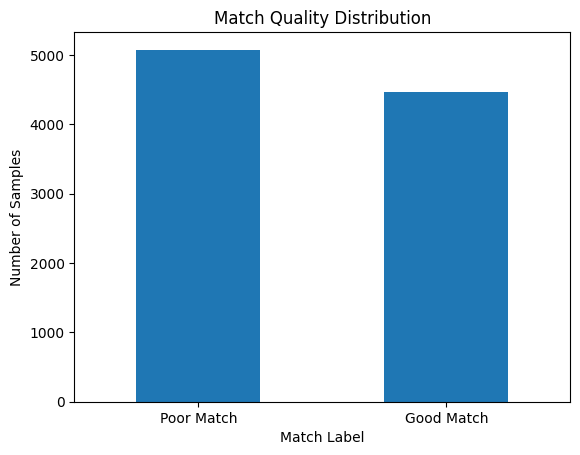

In [7]:
class_counts.plot(kind="bar")

plt.title("Match Quality Distribution")
plt.xlabel("Match Label")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.show()

In [8]:
X = df["combined_text"]
y = df["match_label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 7635
Testing samples: 1909


In [9]:
baseline_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2)
        )
    ),
    (
        "classifier",
        DummyClassifier(
            strategy="most_frequent"
        )
    )
])

baseline_model.fit(X_train, y_train)

baseline_pred = baseline_model.predict(X_test)

print(
    classification_report(
        y_test,
        baseline_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

  Good Match       0.00      0.00      0.00       894
  Poor Match       0.53      1.00      0.69      1015

    accuracy                           0.53      1909
   macro avg       0.27      0.50      0.35      1909
weighted avg       0.28      0.53      0.37      1909



In [10]:
logistic_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2)
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

logistic_model.fit(X_train, y_train)

logistic_pred = logistic_model.predict(X_test)

In [11]:
random_forest_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2)
        )
    ),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        )
    )
])

random_forest_model.fit(X_train, y_train)

random_forest_pred = random_forest_model.predict(X_test)

In [12]:
def evaluate_model(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true,
            y_pred,
            pos_label="Good Match",
            zero_division=0
        ),
        "Recall": recall_score(
            y_true,
            y_pred,
            pos_label="Good Match",
            zero_division=0
        ),
        "F1": f1_score(
            y_true,
            y_pred,
            pos_label="Good Match",
            zero_division=0
        )
    }

In [13]:
results = pd.DataFrame([
    evaluate_model(
        "Baseline",
        y_test,
        baseline_pred
    ),
    evaluate_model(
        "Logistic Regression",
        y_test,
        logistic_pred
    ),
    evaluate_model(
        "Random Forest",
        y_test,
        random_forest_pred
    )
])

results

,Model,Accuracy,Precision,Recall,F1
0,Baseline,0.531692,0.000000,0.000000,0.000000
1,Logistic Regression,0.767941,0.748075,0.760626,0.754298
2,Random Forest,0.794657,0.774017,0.793065,0.783425


In [14]:
print(
    classification_report(
        y_test,
        logistic_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

  Good Match       0.75      0.76      0.75       894
  Poor Match       0.79      0.77      0.78      1015

    accuracy                           0.77      1909
   macro avg       0.77      0.77      0.77      1909
weighted avg       0.77      0.77      0.77      1909



In [15]:
print(
    classification_report(
        y_test,
        random_forest_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

  Good Match       0.77      0.79      0.78       894
  Poor Match       0.81      0.80      0.80      1015

    accuracy                           0.79      1909
   macro avg       0.79      0.79      0.79      1909
weighted avg       0.80      0.79      0.79      1909



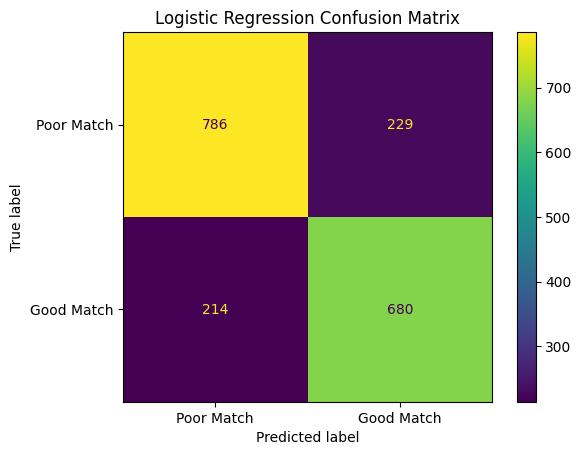

In [16]:
cm_logistic = confusion_matrix(
    y_test,
    logistic_pred,
    labels=["Poor Match", "Good Match"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=["Poor Match", "Good Match"]
)

disp.plot()

plt.title("Logistic Regression Confusion Matrix")
plt.show()

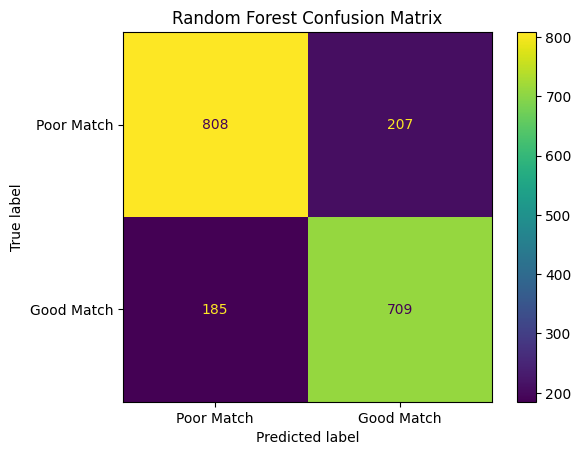

In [17]:
cm_rf = confusion_matrix(
    y_test,
    random_forest_pred,
    labels=["Poor Match", "Good Match"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Poor Match", "Good Match"]
)

disp.plot()

plt.title("Random Forest Confusion Matrix")
plt.show()

In [18]:
results_path = os.path.join(
    "..",
    "Data",
    "classification_results.csv"
)

results.to_csv(
    results_path,
    index=False
)

print(f"Results saved to: {results_path}")

Results saved to: ..\Data\classification_results.csv


In [19]:
models_dir = os.path.join(
    "..",
    "Models"
)

os.makedirs(models_dir, exist_ok=True)

joblib.dump(
    logistic_model,
    os.path.join(
        models_dir,
        "logistic_regression_model.pkl"
    )
)

joblib.dump(
    random_forest_model,
    os.path.join(
        models_dir,
        "random_forest_model.pkl"
    )
)

print("Classification models saved.")

Classification models saved.


## Conclusion

The classification experiment predicts whether a candidate-job pair is a Good Match or Poor Match.

The models are evaluated against a simple baseline using Accuracy, Precision, Recall, F1-score, and Confusion Matrix.

The TF-IDF vectorizer is included inside each machine-learning pipeline, so it is fitted only on the training data.

The 0.70 cutoff is an operational threshold used to create the classification labels. It is not an objective hiring threshold.